<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/abandon_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Inicialización e Importación de Librerías**

# **Rotación de clientes de telecomunicaciones**
https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data

### **Contexto**

Prediga el comportamiento para fidelizar a sus clientes. Puede analizar todos los datos relevantes de los clientes y desarrollar programas de retención de clientes específicos." [Conjuntos de datos de muestra de IBM]

Contenido
Cada fila representa a un cliente, y cada columna contiene los atributos del cliente descritos en la columna Metadatos.

Los datos brutos contienen 7043 filas (clientes) y 21 columnas (características).

La columna **"Churn"** es nuestro objetivo.

In [39]:
import kagglehub
import os
import pandas as pd
from sklearn.model_selection import train_test_split

### **Etapa ETL: Extracción (Descarga y Lectura del Dataset)**

In [55]:
# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)
file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


### **Etapa ETL: Transformación (Exploración Visual Inicial)**

In [56]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### **Etapa ETL: Transformación (Análisis de Metadatos y Estructura)**

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### **Etapa ETL: Transformación (Identificación de Valores Nulos y Duplicados)**

In [58]:
valores_nulos = df.isnull().sum()
valores_duplicados = df.duplicated().sum()
print("Valores nulos, duplicados\n")
print(f"Valores nulos: {valores_nulos}\n")
print(f"Valores duplicados {valores_duplicados}")

Valores nulos, duplicados

Valores nulos: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Valores duplicados 0


In [59]:
# Buscamos en todo el DataFrame celdas que contengan únicamente espacios en blanco (^\s*$)
# axis=0 nos ayuda a sumar cuántas hay por columna

espacios_en_blanco = df.apply(lambda col: col.astype(str).str.contains(r'^\s*$', regex=True).sum())
print("Conteo de valores en blanco por columna:\n", espacios_en_blanco[espacios_en_blanco > 0])

Conteo de valores en blanco por columna:
 TotalCharges    11
dtype: int64


In [60]:
# Convertimos a NanN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Verificar si se introdujeron valores nulos en el proceso
print("Valores nulos en TotalCharges tras la conversión:", df['TotalCharges'].isnull().sum())

# Resumen
df.info()


Valores nulos en TotalCharges tras la conversión: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   ob

### **Etapa ETL: Transformación (Análisis Estadístico Descriptivo Completo)**

In [61]:
estadisticos = df.describe(include="all").T
estadisticos

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Etapa ETL: Transformación (Análisis de Variables Numéricas)**

In [66]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### Etapa ETL: Transformación (Limpieza y Conversión de Tipos de Datos)

### Etapa ETL: Transformación (División del Conjunto de Datos y Variable Objetivo)

In [79]:
traduccion_variables = {
    'customerID': 'ID_Cliente',
    'gender': 'Genero',
    'SeniorCitizen': 'Adulto_Mayor',
    'Partner': 'Tiene_Pareja',
    'Dependents': 'Tiene_Dependientes',
    'tenure': 'Meses_Permanencia',
    'PhoneService': 'Servicio_Telefonico',
    'MultipleLines': 'Lineas_Multiples',
    'InternetService': 'Servicio_Internet',
    'OnlineSecurity': 'Seguridad_Online',
    'OnlineBackup': 'Respaldo_Online',
    'DeviceProtection': 'Proteccion_Dispositivo',
    'TechSupport': 'Soporte_Tecnico',
    'StreamingTV': 'Transmision_TV',
    'StreamingMovies': 'Transmision_Peliculas',
    'Contract': 'Tipo_Contrato',
    'PaperlessBilling': 'Facturacion_Sin_Papel',
    'PaymentMethod': 'Metodo_Pago',
    'MonthlyCharges': 'Cargos_Mensuales',
    'TotalCharges': 'Cargos_Totales',
    'Churn': 'Abandono_Cliente'
}
df = df.rename(columns=traduccion_variables)

In [81]:
### Etapa ETL: Transformación (División del Conjunto de Datos y Variable Objetivo)

datos = df.copy()
y = None
X = None

# Usamos los nombres correctos en español tras el renombrado de columnas
if "Abandono_Cliente" in datos.columns:
    y = datos["Abandono_Cliente"]
    X = datos.drop(columns=["Abandono_Cliente", 'ID_Cliente'])

# Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

Tamaño de X_train: (5634, 19)
Tamaño de X_test: (1409, 19)


In [82]:
orden_ordinales = {
    'Tipo_Contrato': ['Month-to-month', 'One year', 'Two year']
}

numericas_reales = [
    col for col in X_train.columns
    if col in ['Adulto_Mayor', 'Meses_Permanencia', 'Cargos_Mensuales', 'Cargos_Totales']
]

ordinales = [
    col for col in orden_ordinales.keys()
    if col in X_train.columns
]


nominales = [
    col for col in X_train.columns
    if col not in numericas_reales and col not in ordinales and col != 'ID_Cliente'
]

print("\nVariables Numéricas:", numericas_reales)
print("\nVariables Categóricas Nominales:", nominales)
print("\nVariables Categóricas Ordinales:", ordinales)


Variables Numéricas: ['Adulto_Mayor', 'Meses_Permanencia', 'Cargos_Mensuales', 'Cargos_Totales']

Variables Categóricas Nominales: ['Genero', 'Tiene_Pareja', 'Tiene_Dependientes', 'Servicio_Telefonico', 'Lineas_Multiples', 'Servicio_Internet', 'Seguridad_Online', 'Respaldo_Online', 'Proteccion_Dispositivo', 'Soporte_Tecnico', 'Transmision_TV', 'Transmision_Peliculas', 'Facturacion_Sin_Papel', 'Metodo_Pago']

Variables Categóricas Ordinales: ['Tipo_Contrato']


### Etapa ETL: Transformación (Mapa de Calor de Correlaciones de Pearson)

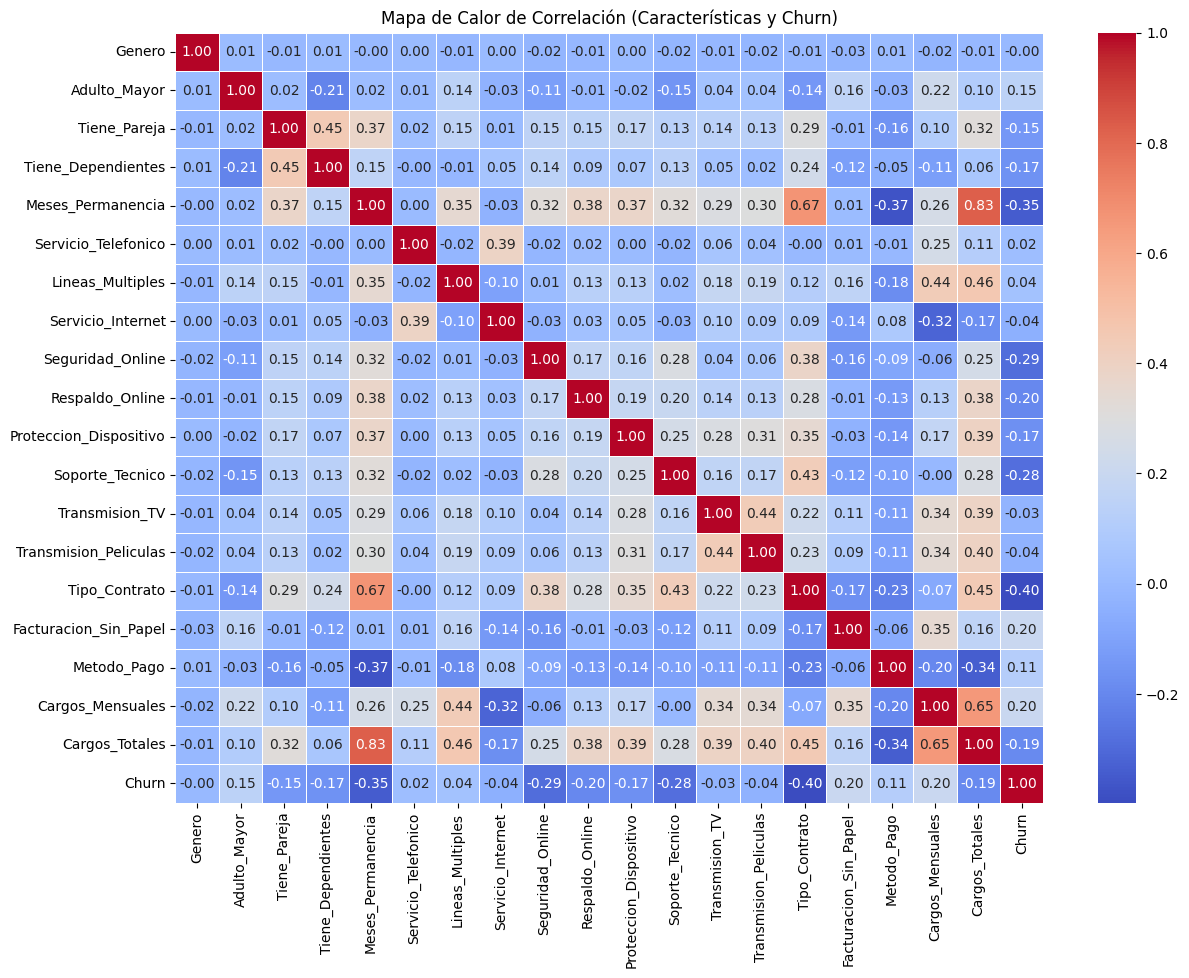

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

# Creamos una copia del set de entrenamiento para no alterar el original
datos_correlacion = X_train.copy()

# Codificamos temporalmente la variable objetivo y_train
datos_correlacion['Churn'] = y_train.map({'Yes': 1, 'No': 0})

# Codificamos las variables categóricas nominales y ordinales como enteros para la correlación
for col in nominales + ordinales:
    if col in datos_correlacion.columns:
        datos_correlacion[col] = datos_correlacion[col].astype('category').cat.codes

# Calculamos la matriz de correlación de Pearson
matriz_corr = datos_correlacion.corr()

# Configuramos y mostramos el mapa de calor
plt.figure(figsize=(14, 10))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar=True
)
plt.title("Mapa de Calor de Correlación (Características y Churn)")
plt.show()

In [84]:
### Etapa ETL: Transformación (Análisis Comparativo: Pearson, Kendall e Información Mutua)

import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif

# Preparamos una copia de entrenamiento codificada para los cálculos numéricos
datos_analisis = X_train.copy()
target = y_train.map({'Yes': 1, 'No': 0})

# Codificamos numéricamente las variables categóricas para los coeficientes de correlación
for col in nominales + ordinales:
    if col in datos_analisis.columns:
         datos_analisis[col] = datos_analisis[col].astype('category').cat.codes

# Tratamiento de valores faltantes temporales para el cálculo (por ejemplo, en Cargos_Totales)
datos_analisis = datos_analisis.fillna(datos_analisis.median())

# 1. Correlación de Pearson
corr_pearson = datos_analisis.apply(lambda col: col.corr(target, method='pearson'))

# 2. Correlación de Kendall (captura relaciones monótonas no necesariamente lineales)
corr_kendall = datos_analisis.apply(lambda col: col.corr(target, method='kendall'))

# 3. Información Mutua (mide cualquier tipo de dependencia estadística, escala >= 0)
mi_valores = mutual_info_classif(datos_analisis, target, random_state=42)
series_mi = pd.Series(mi_valores, index=datos_analisis.columns)

# Consolidamos los resultados en un único DataFrame comparativo
tabla_comparativa = pd.DataFrame({
    'Pearson': corr_pearson,
    'Kendall': corr_kendall,
    'Información Mutua': series_mi
})

# Ordenamos de mayor a menor según la Información Mutua
tabla_comparativa = tabla_comparativa.sort_values(by='Información Mutua', ascending=False)

# Mostramos la tabla formateada
display(tabla_comparativa.style.background_gradient(cmap='viridis', axis=0).format(precision=4))

,Pearson,Kendall,Información Mutua
Tipo_Contrato,-0.3973,-0.3877,0.0954
Seguridad_Online,-0.2930,-0.2920,0.0747
Soporte_Tecnico,-0.2838,-0.2828,0.0684
Meses_Permanencia,-0.3456,-0.2970,0.0645
Servicio_Internet,-0.0448,-0.0244,0.0573
Respaldo_Online,-0.1960,-0.1921,0.0544
Cargos_Mensuales,0.1980,0.1549,0.0479
Metodo_Pago,0.1150,0.1007,0.0460
Cargos_Totales,-0.1944,-0.1832,0.0392
Transmision_TV,-0.0266,-0.0256,0.0341


### **Documentación: Significado de las Variables**

> **Variable Objetivo**
> *   **Abandono_Cliente:** Indica si el cliente canceló su servicio y dejó la compañía (Yes) o si continúa activo (No).
>
> **Variables Demográficas**
> *   **Genero:** Identifica si el cliente es hombre (Male) o mujer (Female).
> *   **Adulto_Mayor:** Variable numérica que indica si el cliente es una persona de la tercera edad (1) o no (0).
> *   **Tiene_Pareja:** Indica si el cliente tiene un compañero sentimental (Yes / No).
> *   **Tiene_Dependientes:** Indica si el cliente tiene personas a su cargo, como hijos o familiares (Yes / No).
>
> **Servicios Contratados**
> *   **Servicio_Telefonico:** Indica si el cliente tiene contratado el servicio de telefonía fija (Yes / No).
> *   **Lineas_Multiples:** Especifica si el cliente tiene una, varias líneas telefónicas o si no cuenta con servicio telefónico.
> *   **Servicio_Internet:** Tipo de conexión de internet del cliente (DSL, Fiber optic o No).
> *   **Seguridad_Online:** Indica si tiene contratado el servicio de seguridad adicional para internet.
> *   **Respaldo_Online:** Indica si cuenta con un servicio de copia de seguridad en la nube.
> *   **Proteccion_Dispositivo:** Indica si el cliente tiene un plan de protección o seguro para sus equipos electrónicos.
> *   **Soporte_Tecnico:** Indica si tiene contratado asistencia técnica prioritaria con la compañía.
> *   **Transmision_TV:** Indica si utiliza la conexión de internet para ver televisión por streaming.
> *   **Transmision_Peliculas:** Indica si utiliza el servicio de internet para ver películas por streaming.
>
> **Información de la Cuenta y Facturación**
> *   **Meses_Permanencia:** Cantidad de meses que el cliente ha estado contratando los servicios de la empresa.
> *   **Tipo_Contrato:** Frecuencia de renovación del contrato (Mes a mes, un año, dos años).
> *   **Facturacion_Sin_Papel:** Indica si el cliente prefiere recibir su factura de manera digital en lugar de impresa (Yes / No).
> *   **Metodo_Pago:** Forma en la que el cliente paga su factura (Cheque electrónico, cheque enviado por correo, transferencia bancaria o tarjeta de crédito).
> *   **Cargos_Mensuales:** El monto total que se le cobra al cliente mensualmente por los servicios.
> *   **Cargos_Totales:** La cantidad acumulada de dinero que el cliente ha pagado a lo largo de todo su tiempo en la compañía.

### Etapa ETL: Transformación (Diccionario de Traducción de Variables al Español)